# MECHA, 10: scaling one tissue

**What you will learn:** change one tissue, or a few cells, or a few walls, without changing the others: slow the
aquaporins of the cortex alone, close walls, and make the fibres of a mature root dead or alive.

**You need:** tutorials 1, 2 and 9. **Run time:** about 20 seconds.

## 1. Parameters and inputs

So far, every change was a **parameter**: one number for the whole root (`kw`, `kaqp`...), given to `simulate`. Some
changes concern only some cells: an inhibitor reaching the outer cells only, a wall damaged, a group of fibres dead.
MECHA takes them as **inputs**: one value per cell or per wall, which another model (of the root's development,
of its regulation) or you give. Three of them:

| input | given on | what it controls | default |
|---|---|---|---|
| `aquaporin_factor` | each cell | its aquaporins' activity, relative to its tissue's | 1 |
| `wall_conductivity_factor` | each wall | its conductivity, relative to what the barriers' rules give it | 1 |
| `living_cell` | each fibre (sclerenchyma cell) | 1 alive, 0 dead | drawn (section 4) |

A solved section keeps all its values in its **data structure** (`result.data_structure`), one array per variable.
To change an input: read the arrays you need, set the input's array, and solve the section again. A small helper
does the last step:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.mecha.geometry import MEMBRANE
from openalea.mecha.simulation import simulate


def solve_again(result):
    """Solve the section *result* again, with its inputs as they are now: its kr and its water uptake."""
    result.scene.run()
    data = result.data_structure
    return pd.Series({"kr": float(data.get("kr")[0]), "uptake": float(data.get("standard_uptake")[0])})


section = simulate()                                  # a Casparian band in the endodermis (barrier 1)
data = section.data_structure
tissue = np.asarray(data.get("tissue"), dtype=object)             # each cell's tissue (walls: None)
reference = solve_again(section)
reference

kr        0.000107
uptake    0.002701
dtype: float64

## 2. The cortex's aquaporins halved

**Aquaporins** are the water channels of the membranes. `aquaporin_factor` scales those of each cell: 0.5 on the
cortex cells halves theirs.

In [2]:
data.set("aquaporin_factor", np.where(tissue == "cortex", 0.5, 1.))
halved = solve_again(section)
same_by_parameter = simulate({"kaqp_cortex_factor": 0.5}).summary[["kr", "uptake"]]
data.set("aquaporin_factor", np.ones(data.n_nodes()))                 # back to 1 everywhere
pd.DataFrame({"reference": reference, "cortex's aquaporins × 0.5": halved,
              "the same by kaqp_cortex_factor": same_by_parameter}).T

,kr,uptake
reference,0.000107,0.002701
cortex's aquaporins × 0.5,0.000106,0.002663
the same by kaqp_cortex_factor,0.000106,0.002663


kr falls by about 1 %: most of the water crosses the cortex along its walls, around the cells (tutorial 1). For a
whole tissue, the parameter `kaqp_cortex_factor` gives the same result. The input goes further: any set of cells,
for instance the cortex cells on the side of a dry patch of soil, or a model computing each cell's aquaporins from
its stress.

## 3. Closing walls

`wall_conductivity_factor` scales a wall's conductivity along it. The walls are not tagged with a tissue: a wall
belongs to the cells it separates, which its **membranes** join it to. This helper finds the walls of a tissue's
cells:

In [3]:
def walls_of(name):
    """The walls of the cells of tissue *name*: those a membrane joins to one of its cells."""
    view = data.to_graph_view()                                       # the section's network: its nodes and edges
    membrane = np.asarray(data.get("network_path")) == MEMBRANE
    cell = np.concatenate([view.tail[membrane], view.head[membrane]])
    wall = np.concatenate([view.head[membrane], view.tail[membrane]])
    return np.unique(wall[tissue[cell] == name])


exodermis_walls = walls_of("exodermis")
one_wall = walls_of("cortex")[:1]
cases = {"reference": None, "one cortex wall closed": one_wall, "the exodermis' walls closed": exodermis_walls}
closed = {}
for name, walls in cases.items():
    factor = np.ones(data.n_nodes())
    if walls is not None:
        factor[walls] = 1e-6                                          # nearly closed
    data.set("wall_conductivity_factor", factor)
    closed[name] = solve_again(section)
data.set("wall_conductivity_factor", np.ones(data.n_nodes()))
pd.DataFrame(closed).T

,kr,uptake
reference,0.000107,0.002701
one cortex wall closed,0.000107,0.002701
the exodermis' walls closed,0.000073,0.001833


- One wall closed changes nothing visible: the water goes round it, through the neighbouring walls.
- All the exodermis' walls closed cut the walls' path under the surface: the water must cross the exodermis' cells,
  and kr falls by about a third, as an exodermal barrier would do.

A wall is "closed" here with a factor of 10⁻⁶, not 0: a wall with nothing conducting around it (a wall lining an
air space, whose membranes conduct nothing) would have no water potential at all, and the solve fails.

**Lowering `kw` for every wall.** Walls lining an air space are half dry: MECHA gives them the mean of `kw` and
`kw_septa`, the conductivity of a dried wall (1.2 × 10⁻⁴ cm² hPa⁻¹ d⁻¹ by default). A dried wall cannot conduct
better than a wet one, so MECHA stops when `kw_septa` is not below `kw`. To lower `kw` below 1.2 × 10⁻⁴, lower
`kw_septa` too:

In [4]:
try:
    simulate({"kw": 2.4e-5})
except ValueError as error:
    print(error)
pd.Series(simulate({"kw": 2.4e-5, "kw_septa": 1.2e-5}).summary[["kr", "uptake"]], name="kw and kw_septa / 10")

MechaHydraulics: kw_septa (0.00012) is not below kw (2.4e-05) in the sections (SubOrgans) [16], whose walls line air spaces (barrier > 0): kw_septa is a desiccated wall's conductivity, the air side of those walls. Lower kw_septa or raise kw


kr        0.000052
uptake    0.001303
Name: kw and kw_septa / 10, dtype: float64

## 4. Dead fibres

In old roots (barrier 11), the **sclerenchyma**, a tissue of **fibres** (long cells with thick lignified walls that
stiffen the root), matures: its walls are lignified (0.1 × `kw`, `kw_sclerenchyma_fraction`), and most fibres die.
A dead fibre has no living content, so its **plasmodesmata**, the channels between neighbouring cells, are closed.
MECHA's parameters:

| parameter | what it controls | default |
|---|---|---|
| `sclerenchyma_dead_fraction` | the share of the fibres that are dead, drawn at random | 0.8 |
| `sclerenchyma_plasmodesmata_factor` | what is left of a living fibre's plasmodesmata | 0.05 |
| `sclerenchyma_seed` | the random draw: another seed, other dead fibres | 0 |

GRANAP's roots have no fibres. Here a small helper turns the outer quarter of the cortex into a ring of fibres, as
some roots have under their exodermis. It adds a step between the anatomy and MECHA (developer tutorial 7 explains
how); you only need to call `fibrous_root`, with MECHA's parameters as with `simulate`:

In [5]:
from dataclasses import dataclass

from openalea.metafspm import CompositeModel, FunctionalComponent, Planting, planting, rate, Scene, state_variable
from openalea.granap.metafspm.architectures import RootAxis
from openalea.granap.metafspm.component import GranapAnatomy, junction_rules
from openalea.mecha.component import SCALES, MechaHydraulics
from openalea.mecha.stand_ins import Development


@dataclass
class Fibres(FunctionalComponent):
    """The outer quarter of the cortex cells (by their distance to the centre) made fibres (sclerenchyma)."""
    tissue: object = state_variable(unit="", description="the cell's tissue, the outer cortex's fibres", default=None,
                                    scale=SCALES.Compartment, location="node", dtype=object, kind="descriptor")

    @rate(include_inactive=True)
    def _tissue(self, tissue, compartment_type, section_x, section_y) -> np.ndarray:
        tissue = np.asarray(tissue, dtype=object).copy()
        cortex = (np.asarray(compartment_type) == 0) & (tissue == "cortex")
        x, y = np.asarray(section_x), np.asarray(section_y)
        distance = np.hypot(x - x[cortex].mean(), y - y[cortex].mean())
        tissue[cortex & (distance > np.quantile(distance[cortex], 0.75))] = "sclerenchyma"
        return tissue


class RootWithFibres(CompositeModel):
    initiators = (RootAxis, GranapAnatomy)
    from_scale, nodes, wiring = "SubOrgan", "Compartment", junction_rules
    parts = {"anatomy": GranapAnatomy, "development": Development, "fibres": Fibres, "hydraulics": MechaHydraulics}
    schedule = ("development", "anatomy", "fibres", "hydraulics")


def fibrous_root(living=None, **parameters):
    """A root section with a ring of fibres, at barrier 11, MECHA's *parameters* changed; *living*: a function giving
    each node's living_cell from the section's data structure (None: drawn). Its kr."""
    scene = Scene(planting([Planting()], RootWithFibres, dict(parameters, mature_barrier=11.)))
    data = scene.populations[0].data_structure
    if living is not None:
        data.set("living_cell", living(data))
    scene.run()
    return float(data.get("kr")[0])

kr with the default draw, with no fibre dead, with all dead, and with living fibres whose plasmodesmata stay open:

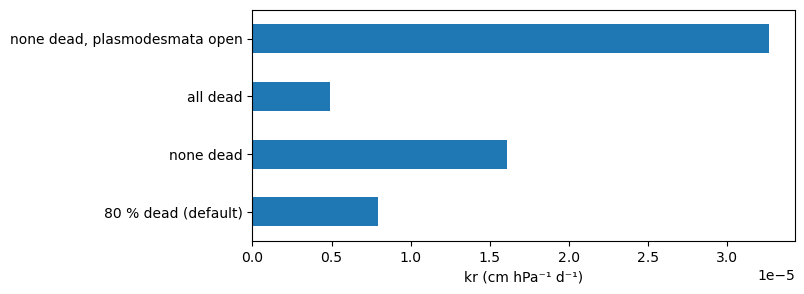

80 % dead (default)              0.000008
none dead                        0.000016
all dead                         0.000005
none dead, plasmodesmata open    0.000033
Name: kr, dtype: float64

In [6]:
fibres = pd.Series({
    "80 % dead (default)": fibrous_root(),
    "none dead": fibrous_root(sclerenchyma_dead_fraction=0.),
    "all dead": fibrous_root(sclerenchyma_dead_fraction=1.),
    "none dead, plasmodesmata open": fibrous_root(sclerenchyma_dead_fraction=0., sclerenchyma_plasmodesmata_factor=1.),
}, name="kr")
fibres.plot.barh(xlabel="kr (cm hPa⁻¹ d⁻¹)", figsize=(7, 3))
plt.show()
fibres

At barrier 11 the endodermis and the exodermis are suberized: their plasmodesmata are the water's main way through
them, and the fibres' ring lies on that way. Dead fibres close it, and kr falls; with every fibre alive and its
plasmodesmata open, kr is that of barrier 8 (the same barriers, without the fibres' maturation).

**Giving the living fibres yourself.** When you know which fibres live (a staining, a model of their death), give
`living_cell` instead of the draw: 1 alive, 0 dead, on each fibre (other cells ignore it). Here the fibres of the
section's left half are alive, the others dead:

In [7]:
def left_half_alive(data):
    x = np.asarray(data.get("section_x"))
    return np.where(x < np.median(x), 1., 0.)


pd.Series({"drawn (80 % dead)": fibres["80 % dead (default)"], "left half alive": fibrous_root(living=left_half_alive)},
          name="kr")

drawn (80 % dead)    0.000008
left half alive      0.000012
Name: kr, dtype: float64

Half the fibres dead, in one block: kr lies between the "all dead" and the "none dead" cases.

## Try it yourself

1. Halve the aquaporins of the endodermis' cells only, with `aquaporin_factor`. Compare with the cortex's: why is
   the effect so much larger?
2. Close the walls of the epidermis instead of the exodermis'. Does kr fall as much? (Look at the water potentials,
   `section.draw("potential")`.)
3. Draw the dead fibres with other seeds (`sclerenchyma_seed`): how much does kr vary from one draw to another?

**Going further:** developer tutorial 11 shows how the walls' and membranes' conductances are built from these
values.